# 10 - The Full Autonomy Stack

## Imports

In [1]:
import time
import heapq
import numpy as np
import matplotlib.pyplot as plt

## Putting the Layers Together

Every notebook so far has built one piece of the autonomy problem in isolation. This one puts those pieces together on a single robot, in a single match-style episode, so you can see what each piece is *for* by watching what goes wrong when it's missing.

A real autonomy stack is built in layers. Each one answers a different question, and each runs at a different speed.

| Layer | The question it answers | How often it runs | Where we built it |
|---|---|---|---|
| Global planner | What route should I take to the goal? | Rarely: once at the start, then only when asked | Hybrid A\* from `09` |
| Path tracker | How do I steer to stay on that route? | Every tick (20 ms) | Pure Pursuit from `04b` |
| Reactive layer | Is something about to hit me *right now*? | Every tick | Potential field from `09` |
| Supervisor | Can I still trust the plan? | Every tick | New in this notebook |

The planner and the tracker split a job that's too big for either alone.Tthe planner thinks far ahead but is slow, while the tracker is fast but only knows how to follow what it's given. The reactive layer covers what neither of them can see coming, and the supervisor decides when the plan has gone stale and needs replacing.

To keep this notebook runnable on its own, the planner code from `09` is repeated here in a compact form. Nothing in it is new.

## The World

The robot is the same kind we planned for in `09`'s Problem B. It only drives forward, can't turn in place, and can't turn tighter than a 1 meter radius. Its speed tops out at 1.5 m/s, which means its turn rate is capped at `speed / radius`. That cap matters later.

The robot starts out facing away from its goal. Four other robots share the field, and it's worth being specific about what each one is there to test:

- **Parked A and parked B** are known from the start and never move. A good plan just routes around them.
- **The opponent** is driving straight down the field at 0.5 m/s, and it crosses the lane our robot will want to use. A plan made at `t = 0` can't know exactly when it'll be in the way.
- **The gate** is a pair of robots that perception only reports at `t = 6 s`, with a gap between them that's too narrow for our robot to fit through. Think of another alliance rolling into position, or a pair of robots coming out from behind a field element.

Two sizes show up throughout. The planners treat every obstacle as 0.75 m in radius (the footprint plus a safety margin, just like the inflated occupancy grid in `09`). A *crash* is when the robot's center gets within 0.6 m of another robot's center.

In [2]:
FIELD_LENGTH, FIELD_WIDTH = 16.0, 8.0
CELL_SIZE = 0.25
GRID_W, GRID_H = int(FIELD_LENGTH / CELL_SIZE), int(FIELD_WIDTH / CELL_SIZE)
CELL_X = (np.arange(GRID_W) + 0.5) * CELL_SIZE
CELL_Y = (np.arange(GRID_H) + 0.5) * CELL_SIZE
CELL_XX, CELL_YY = np.meshgrid(CELL_X, CELL_Y)

# the robot: drives forward only, can't turn in place (its turn rate is capped by its speed)
V_MAX = 1.5                    # m/s
MIN_RADIUS = 1.0               # m, the tightest circle it can drive
OMEGA_MAX = V_MAX / MIN_RADIUS
DT = 0.02                      # s per tick, the same 20 ms loop as 04b

KEEP_OUT = 0.75                # planners treat every obstacle as this big (footprints + a safety margin)
CRASH_DIST = 0.6               # the robot has actually hit something if its center gets this close to another center

wrap = lambda a: (a + np.pi) % (2 * np.pi) - np.pi

class Obstacle:
    """ Another robot (or object) on the field. It can move at a constant velocity, and it can show up late. """
    def __init__(self, name, position, velocity=(0.0, 0.0), appears_at=0.0):
        self.name = name
        self.position0 = np.array(position, dtype=float)
        self.velocity = np.array(velocity, dtype=float)
        self.appears_at = appears_at

    def position(self, t):
        return self.position0 + self.velocity * t

    def is_static(self):
        return np.linalg.norm(self.velocity) < 0.05

OBSTACLES = [
    Obstacle("parked A", (6.0, 2.4)),
    Obstacle("parked B", (10.0, 6.4)),
    Obstacle("opponent", (8.0, 7.5), velocity=(0.0, -0.5)),
    Obstacle("gate left", (12.0, 3.45), appears_at=6.0),
    Obstacle("gate right", (12.0, 4.55), appears_at=6.0),
]

def visible_obstacles(t):
    """ What perception (05's tracker, in the real robot) reports at time t: positions and velocities. """
    return [(o, o.position(t)) for o in OBSTACLES if t >= o.appears_at]

START = np.array([1.5, 4.0, np.pi])     # facing away from the goal
GOAL = np.array([14.5, 4.0])

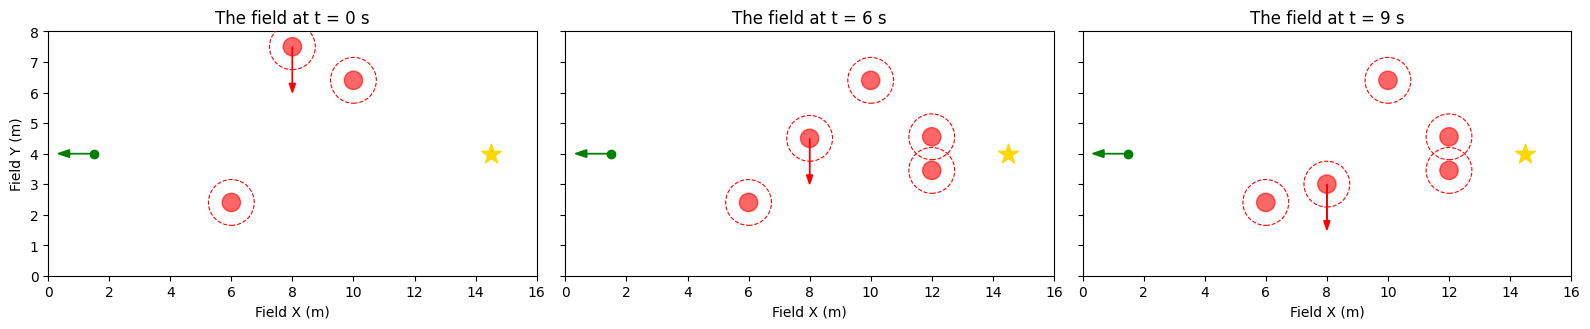

In [3]:
def draw_obstacles(ax, t, show_keep_out=True):
    for o, p in visible_obstacles(t):
        ax.add_patch(plt.Circle(p, 0.3, color="red", alpha=0.6, zorder=3))
        if show_keep_out:
            ax.add_patch(plt.Circle(p, KEEP_OUT, fill=False, edgecolor="red", linestyle="--", linewidth=0.8, zorder=3))
        if not o.is_static():
            ax.arrow(p[0], p[1], 1.2 * o.velocity[0] / np.linalg.norm(o.velocity), 1.2 * o.velocity[1] / np.linalg.norm(o.velocity),
                     head_width=0.2, color="red", zorder=3)

def style_field(ax, title):
    ax.set_xlim(0, FIELD_LENGTH)
    ax.set_ylim(0, FIELD_WIDTH)
    ax.set_aspect("equal")
    ax.set_xlabel("Field X (m)")
    ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(16, 3.6), sharey=True)
for ax, t in zip(axes, [0.0, 6.0, 9.0]):
    draw_obstacles(ax, t)
    ax.arrow(START[0], START[1], 0.8 * np.cos(START[2]), 0.8 * np.sin(START[2]), head_width=0.25, color="green", zorder=4)
    ax.scatter(*START[:2], color="green", zorder=4)
    ax.scatter(*GOAL, marker="*", s=220, color="gold", zorder=4)
    style_field(ax, f"The field at t = {t:.0f} s")
axes[0].set_ylabel("Field Y (m)")
plt.tight_layout()
plt.show()

## Layer 1: The Global Planner

This is the Hybrid A\* planner from `09`, packaged as a single function. It takes a starting pose, a goal, and an occupancy grid, and returns a drivable path.

One change from `09` is worth noting. When we build the occupancy grid, anything that's moving gets filled in along its *predicted* path for the next three seconds, assuming constant velocity. That's the same kind of extrapolation `05`'s tracker would hand us. Without it, a plan made around a moving robot's *current* position would drive straight into where it's about to be.

In [4]:
PREDICTION_HORIZON = 3.0       # s of constant-velocity prediction for anything that's moving

def occupancy_from(seen, t):
    """ The occupancy grid from 09, built from what perception reports at time t. Anything that's moving is also
    filled in along its predicted path (constant velocity, like 05's tracker would extrapolate) for the next few seconds. """
    occupancy = np.zeros((GRID_H, GRID_W))
    for o, p in seen:
        offsets = [0.0] if o.is_static() else np.arange(0.0, PREDICTION_HORIZON + 1e-9, 0.25)
        for dt in offsets:
            q = p + o.velocity * dt
            occupancy[np.hypot(CELL_XX - q[0], CELL_YY - q[1]) <= KEEP_OUT] = 1
    return occupancy

def free_at(occupancy, xy):
    if not (0 <= xy[0] < FIELD_LENGTH and 0 <= xy[1] < FIELD_WIDTH):
        return False
    return occupancy[int(xy[1] / CELL_SIZE), int(xy[0] / CELL_SIZE)] == 0

PLAN_SPEED, ARC_TIME = 1.0, 0.8
PLAN_TURNS = np.linspace(-1.0, 1.0, 9)            # rad/s at 1 m/s, so the same 1 m minimum radius
HEADING_BINS = 24

def drive_arc(state, omega, n_steps=8):
    x, y, theta = state
    dt = ARC_TIME / n_steps
    points = []
    for _ in range(n_steps):
        x += PLAN_SPEED * np.cos(theta) * dt
        y += PLAN_SPEED * np.sin(theta) * dt
        theta = wrap(theta + omega * dt)
        points.append([x, y, theta])
    return np.array(points)

def distance_to_goal_map(occupancy, goal_xy):
    dist = np.full(occupancy.shape, np.inf)
    goal_cell = (int(goal_xy[1] / CELL_SIZE), int(goal_xy[0] / CELL_SIZE))
    dist[goal_cell] = 0.0
    queue = [(0.0, goal_cell)]
    while queue:
        d, (r, c) = heapq.heappop(queue)
        if d > dist[r, c]:
            continue
        for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1), (-1, -1), (-1, 1), (1, -1), (1, 1)]:
            nr, nc = r + dr, c + dc
            if 0 <= nr < GRID_H and 0 <= nc < GRID_W and occupancy[nr, nc] == 0:
                nd = d + np.hypot(dr, dc) * CELL_SIZE
                if nd < dist[nr, nc]:
                    dist[nr, nc] = nd
                    heapq.heappush(queue, (nd, (nr, nc)))
    return dist

def plan_path(start_pose, goal_xy, occupancy, goal_tol=0.6, max_expansions=20000):
    """ Hybrid A* (from 09). Returns the planned path as an (N, 2) array of points, or None if there isn't one. """
    occupancy = occupancy.copy()
    occupancy[np.hypot(CELL_XX - start_pose[0], CELL_YY - start_pose[1]) <= 0.5] = 0      # we're standing here, so it's free
    dist_map = distance_to_goal_map(occupancy, goal_xy)
    key = lambda s: (int(s[0] / CELL_SIZE), int(s[1] / CELL_SIZE), int((s[2] % (2 * np.pi)) / (2 * np.pi / HEADING_BINS)))
    h = lambda s: dist_map[int(s[1] / CELL_SIZE), int(s[0] / CELL_SIZE)]
    states, parents, arcs = [np.asarray(start_pose, dtype=float)], [-1], [None]
    best_cost = {key(states[0]): 0.0}
    queue = [(h(states[0]), 0.0, 0)]
    expansions = 0
    while queue and expansions < max_expansions:
        _, g, i = heapq.heappop(queue)
        if g > best_cost[key(states[i])] + 1e-9:
            continue
        expansions += 1
        if np.linalg.norm(states[i][:2] - goal_xy) < goal_tol:
            chain = [i]
            while parents[chain[-1]] != -1:
                chain.append(parents[chain[-1]])
            return np.vstack([states[chain[-1]][:2]] + [arcs[k][:, :2] for k in chain[::-1][1:]])
        for omega in PLAN_TURNS:
            arc = drive_arc(states[i], omega)
            if not all(free_at(occupancy, p[:2]) for p in arc):
                continue
            new_g = g + PLAN_SPEED * ARC_TIME + 0.1 * abs(omega)
            k = key(arc[-1])
            if new_g < best_cost.get(k, np.inf):
                best_cost[k] = new_g
                states.append(arc[-1]); parents.append(i); arcs.append(arc)
                heapq.heappush(queue, (new_g + h(arc[-1]), new_g, len(states) - 1))
    return None

Planned 161 points (16.0 m) in 23 ms


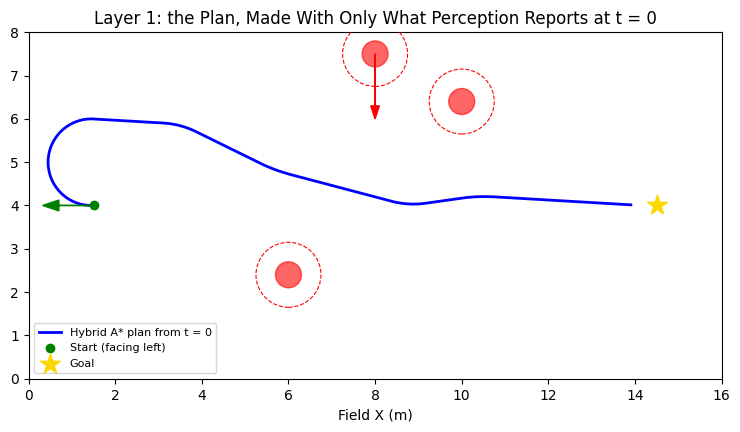

In [5]:
t0 = time.perf_counter()
initial_path = plan_path(START, GOAL, occupancy_from(visible_obstacles(0.0), 0.0))
print(f"Planned {len(initial_path)} points ({np.sum(np.linalg.norm(np.diff(initial_path, axis=0), axis=1)):.1f} m) in {(time.perf_counter() - t0) * 1000:.0f} ms")

fig, ax = plt.subplots(figsize=(10, 4.5))
draw_obstacles(ax, 0.0)
ax.plot(initial_path[:, 0], initial_path[:, 1], "-", color="blue", linewidth=2, label="Hybrid A* plan from t = 0")
ax.arrow(START[0], START[1], 0.8 * np.cos(START[2]), 0.8 * np.sin(START[2]), head_width=0.25, color="green", zorder=4)
ax.scatter(*START[:2], color="green", zorder=4, label="Start (facing left)")
ax.scatter(*GOAL, marker="*", s=220, color="gold", zorder=4, label="Goal")
style_field(ax, "Layer 1: the Plan, Made With Only What Perception Reports at t = 0")
ax.legend(loc="lower left", fontsize=8)
plt.show()

The plan swings up and around to turn the robot, then heads for the goal along a clear lane. It's a good plan for the world as it looked at `t = 0`, which is the only world the planner knows about.

## Layer 2: The Path Tracker

The planner hands us a list of points. Something has to turn that list into steering commands, and that's Pure Pursuit, ported from `04b`'s `PurePursuitDemo.java`. The idea is the same: pick a point on the path one lookahead distance ahead, compute the arc that would carry the robot there, and steer along it. We recompute the target every tick.

The planner's points are about 10 cm apart, so walking forward through the list behaves like the continuous lookahead from the original paper. One more thing from the robot model is that whatever curvature the tracker asks for, the robot can't turn faster than `speed / radius`, so the simulator clips the command to that limit.

In [6]:
LOOKAHEAD = 1.2

def pure_pursuit(pose, path, last_index):
    """ Same idea as 04b: walk forward from the last-targeted point (never backward) until we find one at least
    LOOKAHEAD away, then steer along the arc that would carry the robot there. Returns (curvature, index). """
    index = last_index
    while index < len(path) - 1 and np.hypot(*(path[index] - pose[:2])) < LOOKAHEAD:
        index += 1
    dx, dy = path[index] - pose[:2]
    local_y = -dx * np.sin(pose[2]) + dy * np.cos(pose[2])        # lateral offset, in the robot's own frame
    dist = np.hypot(dx, dy)
    return (2.0 * local_y / dist ** 2 if dist > 1e-6 else 0.0), index

def steer_toward(pose, target_xy, gain=2.0):
    """ For when there's no path to follow: just turn toward the target point. """
    dx, dy = target_xy - pose[:2]
    return gain * wrap(np.arctan2(dy, dx) - pose[2])

## Layer 3: The Reactive Layer

This is `09`'s potential field in a cheap layer that keeps the robot out of trouble at every tick, no matter what the plan says. Each nearby obstacle pushes the robot away, and the robot turns toward the net push. It also slows down as things get close.

There are two changes from `09`, and both come from this robot's minimum turning radius. The first is a wider influence radius, because a robot that can't turn sharply has to start steering earlier. The second is a floor on its speed. For this robot, braking is a poor way to avoid something, because its turn rate is capped at `speed / radius`. A robot that slows to a crawl in front of an obstacle can barely steer, so it tends to stop instead of going around. The floor keeps it moving fast enough to steer, and it only fades to zero when the robot is nearly touching something. The exercises at the end let you see what happens without it.

In [7]:
INFLUENCE = 2.0                # an obstacle farther than this has no effect. This is wider than in 09 on purpose: a robot
                               # with a 1 m minimum turning radius has to start steering early, because slowing down
                               # *reduces* how sharply it can turn (the radius limit means turn rate <= speed / radius)
CREEP_TAPER = 0.1              # ...and fades out over this many meters as it nears the stop distance
CREEP_FLOOR = 0.4              # never slow below 40% of normal speed unless we're nearly touching something
K_REP, K_TURN = 2.0, 0.8

def reactive_layer(pose, obstacle_positions):
    """ Returns (extra turn rate, speed scale between 0 and 1, distance to the nearest obstacle's center). """
    heading = np.array([np.cos(pose[2]), np.sin(pose[2])])
    repulsion = np.zeros(2)
    nearest = np.inf
    for p in obstacle_positions:
        away = pose[:2] - p
        d = np.linalg.norm(away)
        nearest = min(nearest, d)
        if 1e-6 < d < INFLUENCE:
            repulsion += K_REP * (1.0 / d - 1.0 / INFLUENCE) * (1.0 / d ** 2) * (away / d)
    extra_turn = K_TURN * (heading[0] * repulsion[1] - heading[1] * repulsion[0])     # steer toward the "away" direction
    stop_distance = CRASH_DIST + 0.1                  # closer than this, stop dead
    speed_scale = (nearest - stop_distance) / (INFLUENCE - stop_distance)
    creep = CREEP_FLOOR * np.clip((nearest - stop_distance) / CREEP_TAPER, 0.0, 1.0)     # the floor fades out as we get close, so there's no cliff
    speed_scale = float(np.clip(max(speed_scale, creep), 0.0, 1.0))
    return extra_turn, speed_scale, nearest

## Layer 4: The Supervisor

The supervisor is the layer that watches the others. It has one job, which is to decide when the global plan can't be trusted anymore and a new one is needed. It has two ways of deciding.

The first is if the path ahead is blocked. It looks at the next few meters of the current path, and if any of it runs through something the planner would now refuse to drive through, it asks for a replan. This is the proactive trigger. It only considers things that sit still. Anything that's moving is the reactive layer's problem, since by the time a plan accounted for it, it would have moved.

The second is if we're stalled. The robot has made almost no progress toward the goal in the last few seconds. This is the fallback for when the reactive layer has gotten stuck. A cooldown stops it from replanning every tick.

In [8]:
def path_is_blocked(path, index, static_positions, horizon=8.0):
    """ Does the next `horizon` meters of the path run through something the planner would now refuse to drive through? """
    ahead = path[index:]
    travelled = np.concatenate([[0.0], np.cumsum(np.linalg.norm(np.diff(ahead, axis=0), axis=1))])
    for point in ahead[travelled <= horizon]:
        for p in static_positions:
            if np.linalg.norm(point - p) < KEEP_OUT:
                return True
    return False

STALL_WINDOW, STALL_PROGRESS = 3.0, 0.4      # less than 0.4 m of progress toward the goal in 3 s counts as stalled
REPLAN_COOLDOWN = 1.5

## The Simulator

Here's all four layers in one loop. Each tick it asks perception what it can see, lets the supervisor decide about replanning, runs the tracker and the reactive layer to get a steering command, and moves the robot.

The function can run the same episode in three different ways, which is the point of the next section:

- **plan only** makes one plan at `t = 0`, then just follows it. No reactive layer, no replanning.
- **reactive only** has no plan at all. It just steers at the goal and avoids whatever is nearby.
- **full stack** has all four layers.

In [9]:
def simulate(mode, t_max=40.0, triggers=("blocked", "stalled")):
    """ Run one episode. mode is one of:
        "plan only"     - plan once at t = 0, then just follow it
        "reactive only" - no plan at all, just steer at the goal and avoid whatever is nearby
        "full stack"    - plan, follow, avoid, and replan when the supervisor says the plan can't be trusted """
    pose = START.copy()
    t = 0.0
    path, path_index = None, 0
    if mode != "reactive only":
        path = plan_path(pose, GOAL, occupancy_from(visible_obstacles(0.0), 0.0))
        assert path is not None, "no initial plan"
    log = {"t": [], "pose": [], "speed": [], "clearance": [], "reactive_on": [], "replans": [], "plans": [], "attempts": []}
    if path is not None:
        log["plans"].append((0.0, path.copy()))
    progress_history, last_replan = [], -np.inf
    outcome = "ran out of time"

    while t < t_max:
        seen = visible_obstacles(t)
        positions = [p for _, p in seen]
        static_positions = [p for o, p in seen if o.is_static()]
        goal_distance = np.linalg.norm(GOAL - pose[:2])

        # supervisor (full stack only)
        if mode == "full stack":
            progress_history.append((t, goal_distance))
            window = [d for (tt, d) in progress_history if t - tt <= STALL_WINDOW]
            stalled = t - progress_history[0][0] >= STALL_WINDOW and (max(window) - min(window)) < STALL_PROGRESS and goal_distance > 1.0
            blocked = path_is_blocked(path, path_index, static_positions)
            blocked, stalled = blocked and "blocked" in triggers, stalled and "stalled" in triggers
            if (blocked or stalled) and t - last_replan >= REPLAN_COOLDOWN:
                new_path = plan_path(pose, GOAL, occupancy_from(seen, t))
                last_replan = t
                log["attempts"].append((t, "blocked path" if blocked else "stalled", new_path is not None))
                if new_path is not None:
                    path, path_index = new_path, 0
                    log["replans"].append((t, "blocked path" if blocked else "stalled"))
                    log["plans"].append((t, new_path.copy()))
                    progress_history = [(t, goal_distance)]

        # layers 2 and 3: tracker + reactive
        if mode == "plan only":
            curvature, path_index = pure_pursuit(pose, path, path_index)
            speed = V_MAX * min(1.0, max(goal_distance / 1.5, 0.3))
            omega = curvature * speed
            reactive_on, clearance = False, min([np.linalg.norm(pose[:2] - p) for p in positions], default=np.inf)
        else:
            extra_turn, speed_scale, clearance = reactive_layer(pose, positions)
            if mode == "full stack":
                curvature, path_index = pure_pursuit(pose, path, path_index)
                speed = V_MAX * min(1.0, max(goal_distance / 1.5, 0.3))
                omega = curvature * speed + extra_turn
            else:
                speed = V_MAX * min(1.0, max(goal_distance / 1.5, 0.3))
                omega = steer_toward(pose, GOAL) + extra_turn
            speed *= speed_scale
            reactive_on = speed_scale < 0.6 or abs(extra_turn) > 0.3          # "active" = it is meaningfully changing the command

        omega = float(np.clip(omega, -speed / MIN_RADIUS, speed / MIN_RADIUS))     # can't turn tighter than the radius allows

        pose = pose + np.array([speed * np.cos(pose[2]) * DT, speed * np.sin(pose[2]) * DT, omega * DT])
        pose[2] = wrap(pose[2])
        t += DT
        for k, v in zip(("t", "pose", "speed", "clearance", "reactive_on"), (t, pose.copy(), speed, clearance, reactive_on)):
            log[k].append(v)

        true_positions = [o.position(t) for o in OBSTACLES if t >= o.appears_at]
        if any(np.linalg.norm(pose[:2] - p) < CRASH_DIST for p in true_positions):
            outcome = "crashed"
            break
        if np.linalg.norm(GOAL - pose[:2]) < 0.5:
            outcome = "reached the goal"
            break
        if mode == "reactive only" and t > 8 and len(log["speed"]) > 150 and max(log["speed"][-150:]) < 0.05:
            outcome = "stalled"
            break

    log = {k: v if k in ("replans", "plans", "attempts") else np.array(v) for k, v in log.items()}
    log["outcome"] = outcome
    return log

## Three Ways to Drive the Same Match

Same robot, same field, same obstacles, three different stacks. Whatever happens, happens for a reason you can trace to a missing layer.

                outcome              time (s)  dist to goal (m)  closest approach (m)  replans
plan only       crashed                   6.3               7.1                  0.59        0
reactive only   stalled                  14.5               3.3                  0.70        0
full stack      reached the goal         17.0               0.5                  0.77        1

(a crash is a closest approach under 0.6 m)


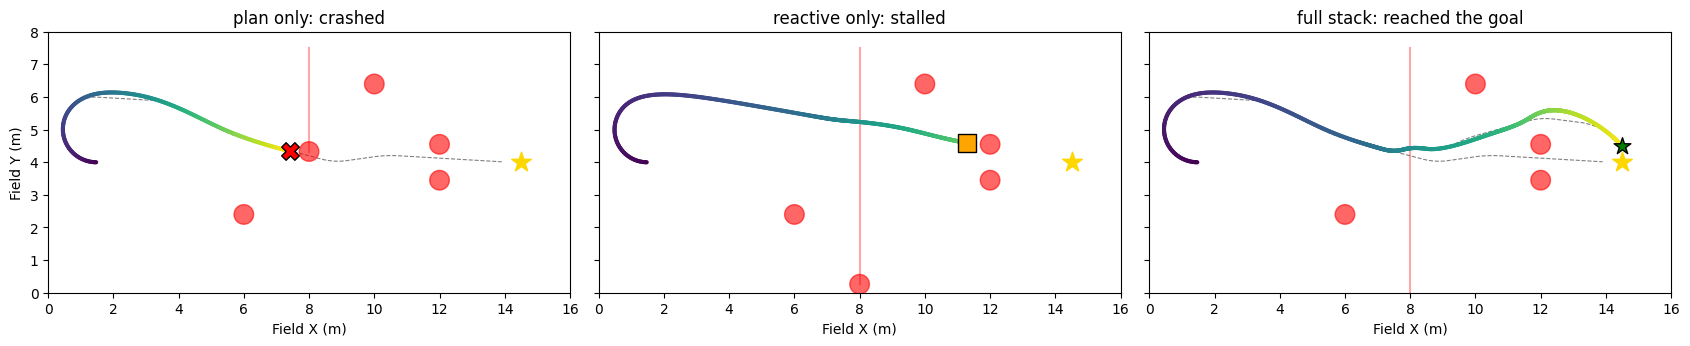

In [10]:
def closest_approach(log):
    dists = []
    for t, pose in zip(log["t"], log["pose"]):
        dists.append(min(np.linalg.norm(pose[:2] - o.position(t)) for o in OBSTACLES if t >= o.appears_at))
    return min(dists)

runs = {mode: simulate(mode) for mode in ("plan only", "reactive only", "full stack")}

print(f"{'':<16}{'outcome':<20}{'time (s)':>9}{'dist to goal (m)':>18}{'closest approach (m)':>22}{'replans':>9}")
for mode, log in runs.items():
    end = log["pose"][-1]
    print(f"{mode:<16}{log['outcome']:<20}{log['t'][-1]:>9.1f}{np.linalg.norm(GOAL - end[:2]):>18.1f}{closest_approach(log):>22.2f}{len(log['replans']):>9}")
print(f"\n(a crash is a closest approach under {CRASH_DIST} m)")

def plot_run(ax, log, title):
    pts = log["pose"]
    ax.scatter(pts[:, 0], pts[:, 1], c=log["t"], s=4, cmap="viridis", zorder=4)
    for o in OBSTACLES:
        if not o.is_static():
            ts = np.linspace(o.appears_at, log["t"][-1], 30)
            track = np.array([o.position(t) for t in ts])
            ax.plot(track[:, 0], track[:, 1], "-", color="red", alpha=0.35, zorder=2)
        ax.add_patch(plt.Circle(o.position(log["t"][-1]), 0.3, color="red", alpha=0.6, zorder=3))
    for _, plan in log["plans"]:
        ax.plot(plan[:, 0], plan[:, 1], "--", color="gray", linewidth=0.8, zorder=1)
    marker = {"crashed": ("X", "red"), "stalled": ("s", "orange"), "reached the goal": ("*", "green")}.get(log["outcome"])
    if marker:
        ax.scatter(*pts[-1, :2], marker=marker[0], s=160, color=marker[1], zorder=6, edgecolor="black")
    ax.scatter(*GOAL, marker="*", s=220, color="gold", zorder=5)
    style_field(ax, f"{title}: {log['outcome']}")

fig, axes = plt.subplots(1, 3, figsize=(17, 3.8), sharey=True)
for ax, (mode, log) in zip(axes, runs.items()):
    plot_run(ax, log, mode)
axes[0].set_ylabel("Field Y (m)")
plt.tight_layout()
plt.show()

Each of the first two failed in its own way.

Plan only crashed into the opponent. The plan was good for the world at `t = 0`, but it was never updated, and the opponent drove across the planned lane right when the robot arrived. A tracker can only follow a path. It can't notice that something is in the way.

Reactive only got stuck at the gate. With no plan, nothing tells the robot that the way through is closed and it should go around. It drives up to the gate and stops about 0.7 m from one of the gate robots, pointed at it with the goal just beyond. The goal pulls it forward, the obstacle blocks forward motion, and "steer away from whatever is close" has no answer for how to get around it. This is the local minimum from `09` showing up in a real scene. It also never crashed. The reactive layer did exactly its job of keeping the robot away from things, and that's what left it stuck.

The full stack reached the goal. It followed the plan, the reactive layer slowed and steered it clear of the opponent, and the supervisor noticed when the gate made the plan unusable and replaced it with one that goes around.

Here's the full-stack run, one frame at a time. The gray dashed line is whatever plan was active.

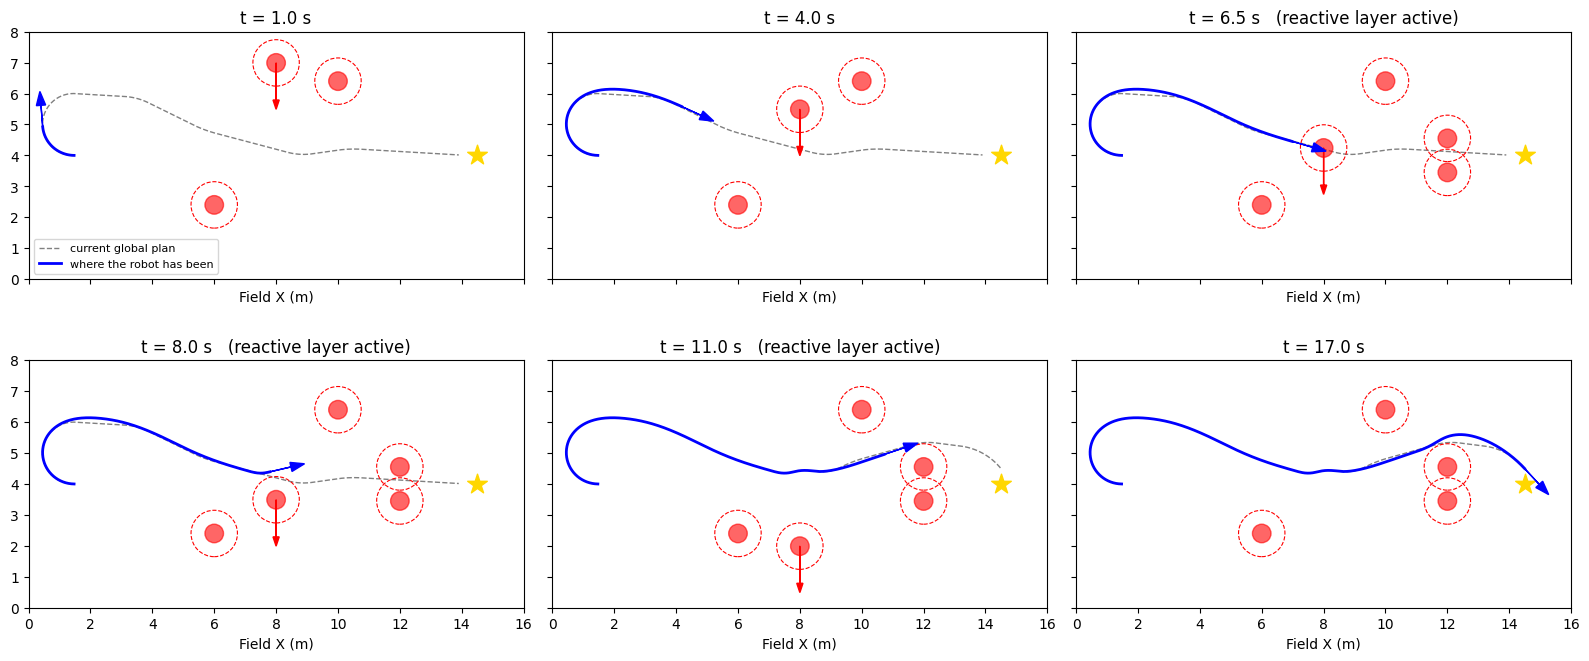

In [11]:
full = runs["full stack"]
moments = [1.0, 4.0, 6.5, 8.0, 11.0, full["t"][-1] - 0.02]
fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex=True, sharey=True)
for ax, t in zip(axes.ravel(), moments):
    i = min(int(t / DT), len(full["t"]) - 1)
    draw_obstacles(ax, full["t"][i])
    plan_now = [plan for tp, plan in full["plans"] if tp <= full["t"][i]][-1]
    ax.plot(plan_now[:, 0], plan_now[:, 1], "--", color="gray", linewidth=1, label="current global plan")
    ax.plot(full["pose"][: i + 1, 0], full["pose"][: i + 1, 1], "-", color="blue", linewidth=2, label="where the robot has been")
    p = full["pose"][i]
    ax.arrow(p[0], p[1], 0.7 * np.cos(p[2]), 0.7 * np.sin(p[2]), head_width=0.3, color="blue", zorder=5)
    ax.scatter(*GOAL, marker="*", s=220, color="gold", zorder=4)
    style_field(ax, f"t = {full['t'][i]:.1f} s" + ("   (reactive layer active)" if full["reactive_on"][i] else ""))
axes[0, 0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

The gray line changes between the fourth and fifth frames. That's the replan. The first plan ran straight through the gate, and the second one swings up and over it.

Here's the same run as a timeline, to show which layer was doing the work at each moment.

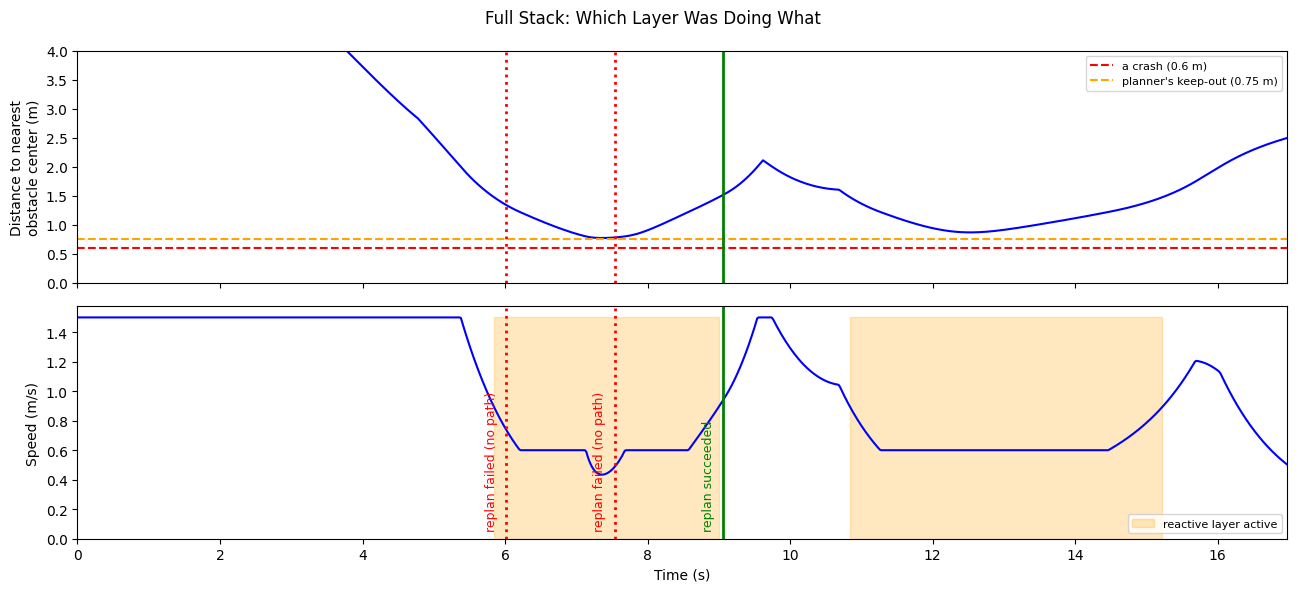

Reactive layer was active for 45% of the run.
Replan attempts (time, trigger, result): (6.0 s, blocked path, failed), (7.5 s, blocked path, failed), (9.1 s, blocked path, ok)


In [12]:
fig, (ax_c, ax_s) = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
t = full["t"]
ax_c.plot(t, full["clearance"], color="blue")
ax_c.axhline(CRASH_DIST, color="red", linestyle="--", label=f"a crash ({CRASH_DIST} m)")
ax_c.axhline(KEEP_OUT, color="orange", linestyle="--", label=f"planner's keep-out ({KEEP_OUT} m)")
ax_c.set_ylim(0, 4)
ax_c.set_ylabel("Distance to nearest\nobstacle center (m)")
ax_c.legend(loc="upper right", fontsize=8)

ax_s.plot(t, full["speed"], color="blue")
ax_s.fill_between(t, 0, V_MAX, where=full["reactive_on"], color="orange", alpha=0.25, label="reactive layer active")
for tr, why, ok in full["attempts"]:
    for ax in (ax_c, ax_s):
        ax.axvline(tr, color="green" if ok else "red", linewidth=2, linestyle="-" if ok else ":")
    ax_s.text(tr - 0.12, 0.05, "replan succeeded" if ok else "replan failed (no path)", color="green" if ok else "red",
              fontsize=9, rotation=90, ha="right", va="bottom")
ax_s.set_ylabel("Speed (m/s)")
ax_s.set_xlabel("Time (s)")
ax_s.set_ylim(0, V_MAX * 1.05)
ax_s.set_xlim(0, t[-1])
ax_s.legend(loc="lower right", fontsize=8)
plt.suptitle("Full Stack: Which Layer Was Doing What")
plt.tight_layout()
plt.show()

print(f"Reactive layer was active for {full['reactive_on'].mean() * 100:.0f}% of the run.")
print("Replan attempts (time, trigger, result): " + ", ".join(f"({tr:.1f} s, {why}, {'ok' if ok else 'failed'})" for tr, why, ok in full["attempts"]))

Read this from left to right. For the first five seconds the tracker has the robot to itself, driving at full speed along the plan. Then the opponent gets close, the first orange band starts, and the reactive layer takes over, slowing and steering the robot clear of it.

The supervisor noticed that the path ahead was blocked the instant the gate appeared at 6 s, but its first two replan attempts failed. With the opponent's predicted path swept across the lane and the gate beyond it, there was simply no way through. The supervisor kept trying every 1.5 seconds, and the reactive layer kept the robot safe in the meantime. The third attempt worked once the opponent had moved on, and from then on the robot followed a new plan around the gate, with the reactive layer active again as it passed close by.

That's the system doing what it's supposed to do. No single layer solved this. The planner couldn't react in time, the reactive layer couldn't see the whole picture, and the supervisor had to wait for a plan that worked.

## Why Does the Supervisor Need Both Triggers?

The supervisor has two ways of deciding to replan. Is the second one enough on its own? Let's turn off the "path is blocked" trigger, so the robot only replans once it's stalled.

Stall trigger only: ran out of time. The supervisor first noticed at t = 14.4 s (the full stack replanned at t = 9.1 s).
Replan attempts: 17, successful: 0


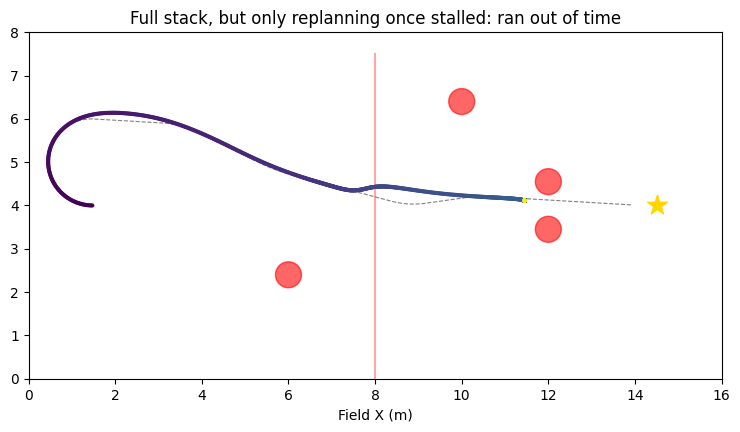

In [13]:
stall_only = simulate("full stack", triggers=("stalled",))
failed = [(t, why) for t, why, ok in stall_only["attempts"] if not ok]
first_stall = stall_only["attempts"][0][0]
print(f"Stall trigger only: {stall_only['outcome']}. The supervisor first noticed at t = {first_stall:.1f} s "
      f"(the full stack replanned at t = {runs['full stack']['replans'][0][0]:.1f} s).")
print(f"Replan attempts: {len(stall_only['attempts'])}, successful: {sum(ok for _, _, ok in stall_only['attempts'])}")

fig, ax = plt.subplots(figsize=(10, 4.5))
plot_run(ax, stall_only, "Full stack, but only replanning once stalled")
plt.show()

It never recovers. The stall trigger does fire, but by then the robot has driven right up to the gate and the reactive layer has braked it to a stop right at the gate, within about 0.9 m of both robots. It can't back up and it can't turn in place, so every replan attempt fails: there's no forward path out of that spot. The proactive trigger is what keeps the robot from getting there in the first place.

The general lesson is that "we've stopped making progress" is a late signal. By the time you see it, you may already be in a place with no good options. A robot that could reverse would have more room to recover, which is one reason real vehicles have that ability. For our robot, noticing the problem early is the only thing that works.

## Relaxing the Assumptions

Until now we've told the stack the truth about everything. It knew every obstacle's exact position and velocity, it assumed every opponent drives in a straight line, the robot did exactly what it was told, and we only ever used one kind of robot. That made the layers easy to understand, but it's also the part of the simulation furthest from a real match.

This section takes those assumptions away one at a time. For each one we'll look at what breaks, what helps, and what doesn't. The experiments run many simulated matches, so this section takes a couple of minutes to run.

### An Opponent Who Changes Its Mind

The tracker in `05` predicts motion by assuming an object keeps doing what it's doing. That's a fine guess most of the time, and it's the guess every plan in this notebook has been built on. But real opponents turn, stop, and swerve, and they tend to do it at the worst possible moment.

To test that, the opponent still drives down its lane at 0.5 m/s, but at some moment we don't announce, it does something else. It might keep going, stop where it is, cut across toward our robot, or turn back the way it came. The function that builds the world takes the behavior and the moment as arguments, so we can try any combination.

In [14]:
class ChangingObstacle(Obstacle):
    """ An obstacle that drives at one velocity, then switches to another at a moment we don't announce. """
    def __init__(self, name, position, velocity, switch_at, velocity_after, appears_at=0.0):
        super().__init__(name, position, velocity, appears_at)
        self.switch_at, self.velocity_after = switch_at, np.array(velocity_after, dtype=float)

    def position(self, t):
        if t <= self.switch_at:
            return self.position0 + self.velocity * t
        return self.position0 + self.velocity * self.switch_at + self.velocity_after * (t - self.switch_at)

    def velocity_at(self, t):
        return self.velocity if t <= self.switch_at else self.velocity_after

def true_velocity(o, t):
    return o.velocity_at(t) if hasattr(o, "velocity_at") else o.velocity

OPPONENT_BEHAVIORS = {
    "keeps going":   (0.0, -0.5),     # what we assumed all along
    "stops":         (0.0, 0.0),      # parks wherever it happens to be
    "cuts toward us": (0.7, -0.2),    # veers east, across our lane
    "turns back":    (-0.7, -0.2),    # veers west, back the way we came from
}

def make_world(behavior, switch_at):
    """ The same field as before, except the opponent does `behavior` starting at time `switch_at`. """
    return [Obstacle("parked A", (6.0, 2.4)),
            Obstacle("parked B", (10.0, 6.4)),
            ChangingObstacle("opponent", (8.0, 7.5), (0.0, -0.5), switch_at, OPPONENT_BEHAVIORS[behavior]),
            Obstacle("gate left", (12.0, 3.45), appears_at=6.0),
            Obstacle("gate right", (12.0, 4.55), appears_at=6.0)]

The stack also needs a new way to learn about the world. Until now every layer read the true positions and velocities directly. From here on, they come from a perception object, which hands over one entry per obstacle: an estimate of where it is, and how fast it's moving. The default is the truth, exactly as before. Later on we'll swap in something worse.

In [15]:
class Track:
    """ What the stack knows about one obstacle: a name and a velocity estimate. """
    def __init__(self, name, velocity):
        self.name, self.velocity = name, np.asarray(velocity, dtype=float)

    def is_static(self):
        return np.linalg.norm(self.velocity) < 0.2        # anything slower than this is treated as parked

class PerfectPerception:
    """ What every simulation so far has used: the truth. """
    def observe(self, t, obstacles):
        return [(Track(o.name, true_velocity(o, t)), o.position(t)) for o in obstacles if t >= o.appears_at]

Next, we need a new way of guessing the future. A constant-velocity predictor gives one future. A multi-hypothesis predictor gives several, each with a probability, which is the same format `07`'s model produces. The hypotheses here are set by hand (it keeps going, it stops, it turns hard left, it turns hard right) as a stand-in for what a trained model would output, since `07`'s network was trained on a different, synthetic problem.

Using several futures means changing two things. The planner's occupancy grid from `09` now holds a probability in each cell, which is the total probability of every predicted future that sweeps through it, and a cell counts as blocked once that probability passes a threshold. A low threshold makes a cautious planner. The supervisor uses the expected collision probability idea from `08`. It walks along the next few meters of the plan, works out when the robot would be at each point, and adds up the probability of every predicted future that has something there at that moment.

A cautious planner has one more problem, which is that it can block off so much of the field that no path exists. So the planner tries its most cautious setting first, and if that leaves no path, it relaxes the threshold and tries again.

In [16]:
def rotate(v, degrees):
    a = np.radians(degrees)
    return np.array([np.cos(a) * v[0] - np.sin(a) * v[1], np.sin(a) * v[0] + np.cos(a) * v[1]])

def constant_velocity_predictor(track, position):
    """ One future: it keeps doing whatever it's doing. """
    return [(1.0, track.velocity)]

def multi_hypothesis_predictor(track, position):
    """ Several futures, each with a probability, in the same format as 07's output. I chose these by hand, as a
    stand-in for what a trained model would produce: it keeps going, it stops, or it turns hard either way. """
    if track.is_static():
        return [(1.0, np.zeros(2))]                       # something parked is assumed to stay parked
    v = track.velocity
    return [(0.4, v), (0.2, np.zeros(2)), (0.2, rotate(v, 70)), (0.2, rotate(v, -70))]

def risk_probability(seen, predictor, horizon=6.0):
    """ Like 09's occupancy grid, except each cell gets a *probability* of being in someone's way: the total probability
    of every predicted future that sweeps through it in the next `horizon` seconds. """
    probability = np.zeros((GRID_H, GRID_W))
    for track, p in seen:
        for weight, velocity in predictor(track, p):
            swept = np.zeros((GRID_H, GRID_W), dtype=bool)
            for dt in ([0.0] if np.linalg.norm(velocity) < 0.05 else np.arange(0.0, horizon + 1e-9, 0.25)):
                q = p + velocity * dt
                swept |= np.hypot(CELL_XX - q[0], CELL_YY - q[1]) <= KEEP_OUT
            probability += weight * swept
    return probability

def risk_occupancy(seen, predictor, threshold, horizon=6.0):
    """ A cell counts as occupied once its probability reaches `threshold`. A lower threshold is a more cautious planner. """
    return (risk_probability(seen, predictor, horizon) >= threshold - 1e-9).astype(float)

def path_collision_risk(path, index, seen, predictor, horizon=8.0, speed=1.2, look_ahead_time=5.0):
    """ The expected-collision-probability idea from 08, applied to the plan: walk along the next few meters of path,
    work out when the robot would be at each point, and add up the probability of every predicted future that
    has something there at that moment. """
    ahead = path[index:]
    travelled = np.concatenate([[0.0], np.cumsum(np.linalg.norm(np.diff(ahead, axis=0), axis=1))])
    keep = (travelled <= horizon) & (travelled / speed <= look_ahead_time)
    points, times = ahead[keep], travelled[keep] / speed
    survive = 1.0
    for track, p in seen:
        risk = 0.0
        for weight, velocity in predictor(track, p):
            at_those_times = p[None, :] + velocity[None, :] * times[:, None]
            if np.min(np.linalg.norm(points - at_those_times, axis=1)) < KEEP_OUT:
                risk += weight
        survive *= 1.0 - min(risk, 1.0)
    return 1.0 - survive

Here's what each predictor thinks the opponent might do next, drawn as the probability that each part of the field ends up in the way. The constant-velocity predictor blocks a single lane. The multi-hypothesis predictor blocks that lane too, but also lightly shades the areas the opponent could swerve into.

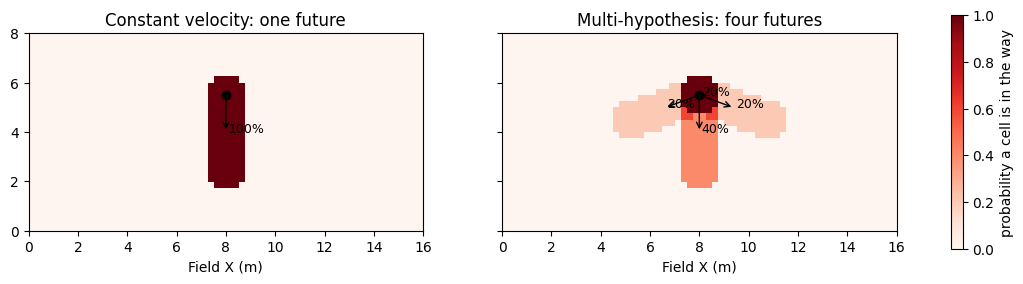

In [17]:
# the two ways of guessing the future that we'll compare, each with the planning settings that suit it
CV_CONFIG = dict(predictor=constant_velocity_predictor, occupancy_threshold=0.5, sweep_horizon=6.0)
MH_CONFIG = dict(predictor=multi_hypothesis_predictor, occupancy_threshold=(0.2, 0.45), sweep_horizon=6.0)

# what the two predictors think the opponent might do next, drawn as a probability map
opponent_now = np.array([8.0, 5.5])
opponent_track = Track("opponent", (0.0, -0.5))
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, (title, predictor) in zip(axes, [("Constant velocity: one future", constant_velocity_predictor),
                                         ("Multi-hypothesis: four futures", multi_hypothesis_predictor)]):
    image = ax.imshow(risk_probability([(opponent_track, opponent_now)], predictor), origin="lower",
                      extent=[0, FIELD_LENGTH, 0, FIELD_WIDTH], cmap="Reds", vmin=0, vmax=1)
    ax.scatter(*opponent_now, color="black", zorder=3)
    for weight, velocity in predictor(opponent_track, opponent_now):
        end = opponent_now + velocity * 3.0
        ax.annotate("", xy=end, xytext=opponent_now, arrowprops=dict(arrowstyle="->", color="black"))
        ax.text(end[0] + 0.1, end[1], f"{weight:.0%}", fontsize=9)
    style_field(ax, title)
fig.colorbar(image, ax=axes, label="probability a cell is in the way", shrink=0.8)
plt.show()

The simulator is rewritten here with the assumptions turned into parameters: what the stack perceives, how it predicts, and how slowly the drivetrain responds. With the defaults it behaves like the simulator from earlier. Two things changed in how the full stack works. The supervisor now uses the risk-based trigger instead of only watching things that sit still. And the prediction window had to be lengthened to six seconds, because at the original three seconds, replanned routes kept slipping past the end of the window and running into the opponent again.

In [18]:
def pure_pursuit_at(pose, path, last_index, lookahead):
    """ pure_pursuit() from earlier, with the lookahead distance as an argument. """
    index = last_index
    while index < len(path) - 1 and np.hypot(*(path[index] - pose[:2])) < lookahead:
        index += 1
    dx, dy = path[index] - pose[:2]
    local_y = -dx * np.sin(pose[2]) + dy * np.cos(pose[2])
    dist = np.hypot(dx, dy)
    return (2.0 * local_y / dist ** 2 if dist > 1e-6 else 0.0), index

def simulate_robust(mode, obstacles, perception=None, predictor=None, occupancy_threshold=0.3, risk_trigger=0.3,
                    actuator_lag=0.0, sweep_horizon=8.0, lookahead=None, start=None, speed_factor=1.0, compensate_lag=False, t_max=40.0):
    """ simulate() from earlier, with the assumptions made explicit and swappable:
        perception   - what the stack sees (default: the truth)
        predictor    - how it guesses the future (default: constant velocity)
        actuator_lag - how slowly the drivetrain follows a command, in seconds (0 = instantly)
    Returns a log dict like simulate() does. """
    perception = perception or PerfectPerception()
    predictor = predictor or constant_velocity_predictor
    pose, t = (START if start is None else np.asarray(start, dtype=float)).copy(), 0.0
    speed_now, omega_now = 0.0, 0.0
    seen = perception.observe(0.0, obstacles)
    thresholds = occupancy_threshold if isinstance(occupancy_threshold, (tuple, list)) else (occupancy_threshold,)

    def plan(p, s):
        """ Plan under the most cautious assumption first. If that leaves no path at all, relax it a step and try again. """
        for threshold in thresholds:
            path = plan_path(p, GOAL, risk_occupancy(s, predictor, threshold, sweep_horizon), max_expansions=3000)
            if path is not None:
                return path
        return None
    path, path_index = (plan(pose, seen), 0) if mode != "reactive only" else (None, 0)
    if mode != "reactive only" and path is None:
        return {"outcome": "no initial plan", "t": np.array([0.0]), "pose": np.array([pose]), "closest": np.inf, "replans": 0}
    progress, last_replan, replans, closest, outcome = [], -np.inf, 0, np.inf, "ran out of time"
    tick, log_t, log_pose, log_speed, log_clear = 0, [], [], [], []

    while t < t_max:
        if tick % 5 == 0 or tick == 0:                    # perception and the supervisor run at 10 Hz
            seen = perception.observe(t, obstacles)
            positions = [p for _, p in seen]
            goal_distance = np.linalg.norm(GOAL - pose[:2])
            if mode == "full stack":
                progress.append((t, goal_distance))
                window = [d for (tt, d) in progress if t - tt <= STALL_WINDOW]
                stalled = t - progress[0][0] >= STALL_WINDOW and max(window) - min(window) < STALL_PROGRESS and goal_distance > 1.0
                risky = path_collision_risk(path, path_index, seen, predictor) >= risk_trigger
                if (risky or stalled) and t - last_replan >= REPLAN_COOLDOWN:
                    last_replan = t
                    new_path = plan(pose, seen)
                    if new_path is not None:
                        path, path_index, replans = new_path, 0, replans + 1
                        progress = [(t, goal_distance)]
        goal_distance = np.linalg.norm(GOAL - pose[:2])
        control_pose = pose
        if compensate_lag and actuator_lag > 0:           # steer from where the robot will be once a command takes effect
            control_pose = pose + np.array([speed_now * np.cos(pose[2]), speed_now * np.sin(pose[2]), omega_now]) * actuator_lag
        extra_turn, speed_scale, clearance = reactive_layer(control_pose, positions)
        cruise = speed_factor * V_MAX * min(1.0, max(goal_distance / 1.5, 0.3))
        if mode == "plan only":
            curvature, path_index = pure_pursuit_at(control_pose, path, path_index, lookahead or LOOKAHEAD)
            speed_cmd, omega_cmd = cruise, curvature * cruise
        elif mode == "full stack":
            curvature, path_index = pure_pursuit_at(control_pose, path, path_index, lookahead or LOOKAHEAD)
            speed_cmd, omega_cmd = cruise * speed_scale, curvature * cruise + extra_turn
        else:
            speed_cmd, omega_cmd = cruise * speed_scale, steer_toward(control_pose, GOAL) + extra_turn

        if actuator_lag > 0:                              # the drivetrain only approaches the command gradually
            speed_now += (speed_cmd - speed_now) * DT / actuator_lag
            omega_now += (omega_cmd - omega_now) * DT / actuator_lag
        else:
            speed_now, omega_now = speed_cmd, omega_cmd
        omega_applied = float(np.clip(omega_now, -speed_now / MIN_RADIUS, speed_now / MIN_RADIUS))
        pose = pose + np.array([speed_now * np.cos(pose[2]) * DT, speed_now * np.sin(pose[2]) * DT, omega_applied * DT])
        pose[2] = wrap(pose[2])
        t += DT
        tick += 1

        true_positions = [o.position(t) for o in obstacles if t >= o.appears_at]
        d_true = min((np.linalg.norm(pose[:2] - p) for p in true_positions), default=np.inf)
        closest = min(closest, d_true)
        if tick % 5 == 0:
            log_t.append(t); log_pose.append(pose.copy()); log_speed.append(speed_now); log_clear.append(d_true)
        if d_true < CRASH_DIST:
            outcome = "hit a robot"
            break
        if not (0.0 <= pose[0] < FIELD_LENGTH and 0.0 <= pose[1] < FIELD_WIDTH):
            outcome = "hit the wall"                      # the reactive layer only knows about robots, not the field walls
            break
        if np.linalg.norm(GOAL - pose[:2]) < 0.5:
            outcome = "reached the goal"
            break
        if mode == "reactive only" and t > 8 and tick > 150 and speed_now < 0.05 and len(log_speed) > 30 and max(log_speed[-30:]) < 0.05:
            outcome = "stalled"
            break
    return {"outcome": outcome, "t": np.array(log_t), "pose": np.array(log_pose), "speed": np.array(log_speed),
            "clearance": np.array(log_clear), "closest": closest, "replans": replans}

Here's the test. We run the full stack with each predictor, for each behavior, with the opponent changing its mind at 17 different moments between 4 and 8 seconds. Each square in the chart is one match.

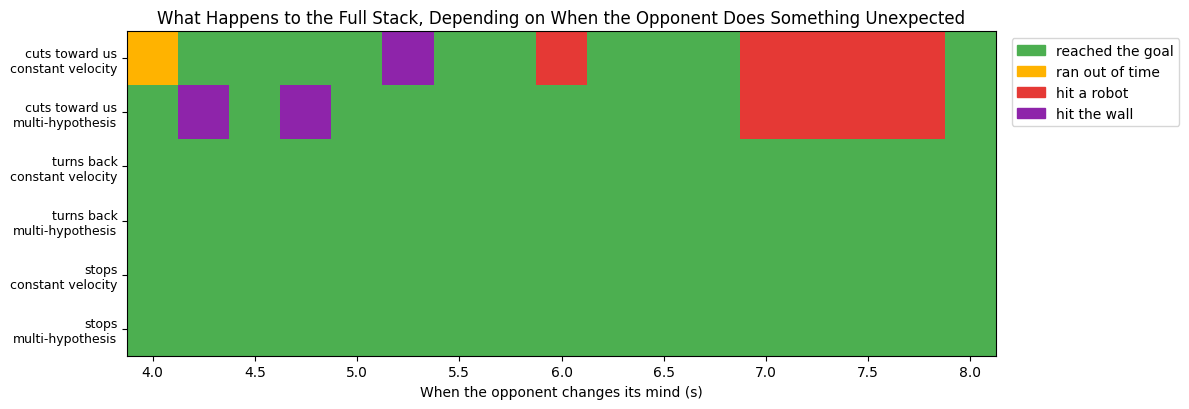

                                    reached  hit robot  hit wall  timed out   mean arrival (s)
cuts toward us, constant velocity     10/17          5         1          1               18.0
cuts toward us, multi-hypothesis      11/17          4         2          0               19.1
turns back, constant velocity         17/17          0         0          0               16.0
turns back, multi-hypothesis          17/17          0         0          0               16.0
stops, constant velocity              17/17          0         0          0               16.0
stops, multi-hypothesis               17/17          0         0          0               16.0


In [19]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# the opponent changes its mind at one of 17 moments, and we run the full stack once for each
switch_times = np.arange(4.0, 8.01, 0.25)
outcome_code = {"reached the goal": 0, "ran out of time": 1, "hit a robot": 2, "hit the wall": 3}
rows, row_labels, summary = [], [], {}
for behavior in ["cuts toward us", "turns back", "stops"]:
    for name, config in [("constant velocity", CV_CONFIG), ("multi-hypothesis", MH_CONFIG)]:
        results = [simulate_robust("full stack", make_world(behavior, sw), t_max=30.0, **config) for sw in switch_times]
        rows.append([outcome_code[r["outcome"]] for r in results])
        row_labels.append(f"{behavior}\n{name}")
        summary[(behavior, name)] = results

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.imshow(rows, aspect="auto", cmap=ListedColormap(["#4caf50", "#ffb300", "#e53935", "#8e24aa"]), vmin=0, vmax=3,
          extent=[switch_times[0] - 0.125, switch_times[-1] + 0.125, len(rows), 0])
ax.set_yticks(np.arange(len(rows)) + 0.5)
ax.set_yticklabels(row_labels, fontsize=9)
ax.set_xlabel("When the opponent changes its mind (s)")
ax.set_title("What Happens to the Full Stack, Depending on When the Opponent Does Something Unexpected")
ax.legend(handles=[Patch(color="#4caf50", label="reached the goal"), Patch(color="#ffb300", label="ran out of time"),
                   Patch(color="#e53935", label="hit a robot"),
                   Patch(color="#8e24aa", label="hit the wall")], loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
plt.show()

print(f"{'':<34}{'reached':>9}{'hit robot':>11}{'hit wall':>10}{'timed out':>11}{'mean arrival (s)':>19}")
for (behavior, name), results in summary.items():
    outcomes = [r["outcome"] for r in results]
    arrivals = [r["t"][-1] for r in results if r["outcome"] == "reached the goal"]
    print(f"{behavior + ', ' + name:<34}{outcomes.count('reached the goal'):>6}/17{outcomes.count('hit a robot'):>11}{outcomes.count('hit the wall'):>10}{outcomes.count('ran out of time'):>11}{np.mean(arrivals):>19.1f}")

The picture is mixed, and it's worth being specific about it. For an opponent that stops or turns back, both predictors reach the goal at every one of the 17 moments. The reactive layer and the replanner handle those without needing to see them coming. "Cuts toward us" is where prediction matters, and there the two predictors fail in different places. Constant velocity fails at seven of the moments, and multi-hypothesis at six. Multi-hypothesis fixes three of constant velocity's failures, including the one where the robot ran out of time. But it introduces two of its own, where the robot dodged the opponent and ended up against the field wall. The reactive layer only knows about robots, so a hard swerve can carry it out of bounds.

The four failures both predictors share are at the end of the window, where the opponent cuts in just as our robot is passing it. Better prediction can't fix those. There isn't enough room for a robot with a 1 meter turning radius to get out of the way, however early it knew. And the multi-hypothesis predictor is slower overall, since it plans more cautiously. Prediction helps at the margin, but how the robot can physically react matters at least as much.

### Noisy Perception

So far the stack saw the opponent's exact position and velocity. A real tracker gets a detection from a camera maybe ten times a second, each one off by some amount, and it sometimes misses one entirely. The simplest thing to do is use the detections as they arrive and get velocity by subtracting consecutive positions, which is what the "raw" perception below does. The better thing is the Kalman filter from `05`, which blends a motion model with each new detection.

In [20]:
MEASURE_EVERY = 0.1            # s between detections (a 10 Hz camera)
POSITION_NOISE = 0.15          # m (1 sigma) on every detection
DROPOUT = 0.1                  # chance that any one detection is missed

class KalmanTrack:
    """ A constant-velocity Kalman filter for one obstacle: the same machinery as SORT in 05. State: x, y, vx, vy. """
    def __init__(self, z, t, accel_noise=1.0):
        self.x = np.array([z[0], z[1], 0.0, 0.0])
        self.P = np.diag([POSITION_NOISE**2, POSITION_NOISE**2, 1.0, 1.0])
        self.t, self.accel_noise = t, accel_noise

    def predict(self, dt):
        F = np.eye(4); F[0, 2] = F[1, 3] = dt
        q = self.accel_noise ** 2
        G = np.array([[dt**2 / 2, 0], [0, dt**2 / 2], [dt, 0], [0, dt]])
        self.x = F @ self.x
        self.P = F @ self.P @ F.T + q * G @ G.T
        self.t += dt

    def update(self, z):
        H = np.zeros((2, 4)); H[0, 0] = H[1, 1] = 1.0
        R = np.eye(2) * POSITION_NOISE ** 2
        K = self.P @ H.T @ np.linalg.inv(H @ self.P @ H.T + R)
        self.x = self.x + K @ (z - H @ self.x)
        self.P = (np.eye(4) - K @ H) @ self.P

class NoisyPerception:
    """ Noisy, delayed, occasionally missing detections. mode is "raw" (use the detections as they come, and get
    velocity by differencing them) or "kalman" (filter them). `delay` is how old a detection is when we get it. """
    def __init__(self, mode, rng, delay=0.0, compensate=True):
        self.mode, self.rng, self.delay, self.compensate = mode, rng, delay, compensate
        self.filters, self.last = {}, {}
        self.next_measure = 0.0

    def observe(self, t, obstacles):
        if t >= self.next_measure:
            self.next_measure += MEASURE_EVERY
            for o in obstacles:
                if t < o.appears_at or self.rng.random() < DROPOUT:
                    continue
                taken_at = max(t - self.delay, o.appears_at)
                z = o.position(taken_at) + self.rng.normal(0, POSITION_NOISE, 2)
                if self.mode == "raw":
                    prev = self.last.get(o.name)
                    vel = (z - prev[1]) / (taken_at - prev[0]) if prev else np.zeros(2)
                    self.last[o.name] = (taken_at, z, vel)
                else:
                    f = self.filters.get(o.name)
                    if f is None:
                        self.filters[o.name] = KalmanTrack(z, taken_at)
                    else:
                        f.predict(taken_at - f.t)
                        f.update(z)
        seen = []
        for o in obstacles:
            if t < o.appears_at:
                continue
            if self.mode == "raw" and o.name in self.last:
                seen.append((Track(o.name, self.last[o.name][2]), self.last[o.name][1]))
            elif self.mode == "kalman" and o.name in self.filters:
                f = self.filters[o.name]
                lead = (t - f.t) if self.compensate else 0.0          # roll the estimate forward to "now"?
                seen.append((Track(o.name, f.x[2:4]), f.x[:2] + f.x[2:4] * lead))
        return seen

Here's what each one says about the opponent's velocity while it drives straight down the field at a steady speed.

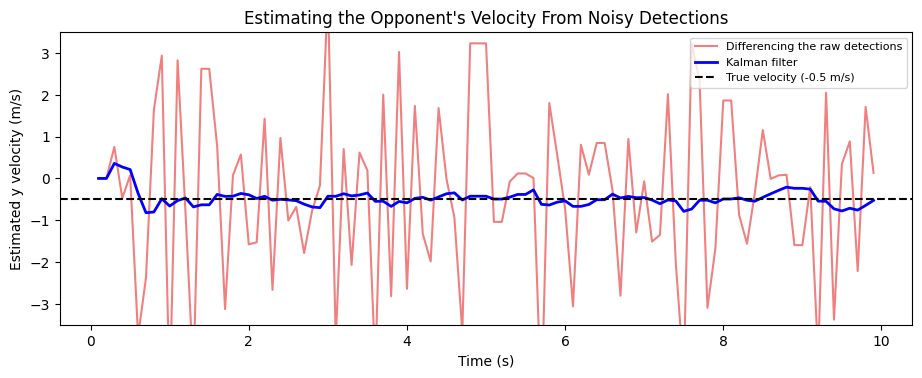

Typical velocity error (after the first second): raw 2.11 m/s, Kalman 0.12 m/s


In [21]:
# what each kind of perception says about the opponent's velocity, while it drives straight down the field at -0.5 m/s
quiet_world = make_world("keeps going", 99.0)
estimates = {}
for mode in ["raw", "kalman"]:
    perception = NoisyPerception(mode, np.random.default_rng(3))
    times, vy = [], []
    for k in range(int(10.0 / 0.1)):
        t = k * 0.1
        for track, _ in perception.observe(t, quiet_world):
            if track.name == "opponent":
                times.append(t)
                vy.append(track.velocity[1])
    estimates[mode] = (times, vy)

plt.figure(figsize=(11, 3.8))
plt.plot(*estimates["raw"], color="lightcoral", label="Differencing the raw detections")
plt.plot(*estimates["kalman"], color="blue", linewidth=2, label="Kalman filter")
plt.axhline(-0.5, color="black", linestyle="--", label="True velocity (-0.5 m/s)")
plt.ylim(-3.5, 3.5)
plt.xlabel("Time (s)")
plt.ylabel("Estimated y velocity (m/s)")
plt.title("Estimating the Opponent's Velocity From Noisy Detections")
plt.legend(loc="upper right", fontsize=8)
plt.show()

errors = {mode: np.sqrt(np.mean((np.array(vy)[10:] + 0.5) ** 2)) for mode, (_, vy) in estimates.items()}
print(f"Typical velocity error (after the first second): raw {errors['raw']:.2f} m/s, Kalman {errors['kalman']:.2f} m/s")

Differencing two noisy positions divides their error by the 0.1 seconds between detections, so an error of about 15 cm turns into a velocity error of roughly 2 m/s, as the printout shows. That velocity is what every prediction is built on. The filter brings the error down to about a tenth of a meter per second.

In [22]:
def random_episode(rng):
    """ One random world: which behavior the opponent picks, and when it does it. """
    return rng.choice(list(OPPONENT_BEHAVIORS)), rng.uniform(3.0, 8.0)

def run_episodes(n, seed=1, make_perception=None, **config):
    """ Run n random episodes of the full stack. Every call with the same seed sees the exact same worlds (and the same
    sensor noise), so different configurations are compared on identical situations. """
    master = np.random.default_rng(seed)
    results = []
    for k in range(n):
        behavior, switch_at = random_episode(master)
        perception = make_perception(np.random.default_rng(10_000 + seed * 1000 + k)) if make_perception else None
        results.append(simulate_robust("full stack", make_world(behavior, switch_at), perception=perception, t_max=30.0, **config))
    return results

def compare(configs, n=30, seed=1):
    """ Run every configuration on the same n episodes and print one row each. """
    print(f"{'':<42}{'reached':>9}{'hit robot':>11}{'hit wall':>10}{'timed out':>11}{'mean arrival (s)':>19}")
    for name, config in configs.items():
        results = run_episodes(n, seed, **config)
        outcomes = [r["outcome"] for r in results]
        arrivals = [r["t"][-1] for r in results if r["outcome"] == "reached the goal"]
        print(f"{name:<42}{outcomes.count('reached the goal'):>6}/{n}{outcomes.count('hit a robot'):>11}{outcomes.count('hit the wall'):>10}"
              f"{outcomes.count('ran out of time'):>11}{np.mean(arrivals) if arrivals else float('nan'):>19.1f}")

EPISODES = 30

Now for the whole stack. These are 30 random matches, where each one has a random opponent behavior at a random moment, and every row below sees exactly the same 30 matches. The only thing that changes is how the stack perceives them. (With only 30 matches, a difference of one or two isn't meaningful, so the things to look at are the big gaps.)

In [23]:
compare({
    "perfect perception":      MH_CONFIG,
    "noisy detections, as-is": dict(MH_CONFIG, make_perception=lambda rng: NoisyPerception("raw", rng)),
    "noisy detections + Kalman": dict(MH_CONFIG, make_perception=lambda rng: NoisyPerception("kalman", rng)),
}, n=EPISODES)

                                            reached  hit robot  hit wall  timed out   mean arrival (s)


perfect perception                            29/30          1         0          0               16.1


noisy detections, as-is                       24/30          2         2          2               18.6


noisy detections + Kalman                     29/30          0         1          0               18.3


Using the noisy detections as they arrive costs the stack five matches. It reaches the goal in 24 of 30, against 29 with perfect perception, with collisions, wall hits, and timeouts all showing up. The filter brings it back to 29 of 30. The filtered stack arrives about two seconds later on average than the one with perfect perception, because smoothed estimates react a little late to what the opponent does.

### Delayed Detections

Even a filtered estimate is old by the time the stack gets it. Camera frames take time to capture, process, and deliver, so the opponent has already moved on. The fix is to roll the estimate forward by the age of the measurement, using the filter's own motion model. Here we give every detection a half-second delay and compare using it as it arrives with rolling it forward to the present.

In [24]:
kalman = lambda **options: (lambda rng: NoisyPerception("kalman", rng, **options))
compare({
    "no delay":                              dict(MH_CONFIG, make_perception=kalman()),
    "0.5 s old, used as it arrives":         dict(MH_CONFIG, make_perception=kalman(delay=0.5, compensate=False)),
    "0.5 s old, rolled forward to now":      dict(MH_CONFIG, make_perception=kalman(delay=0.5, compensate=True)),
}, n=EPISODES)

                                            reached  hit robot  hit wall  timed out   mean arrival (s)


no delay                                      29/30          0         1          0               18.3


0.5 s old, used as it arrives                 26/30          4         0          0               17.8


0.5 s old, rolled forward to now              28/30          2         0          0               18.8


A half-second delay costs a few matches (26 of 30, with four collisions, against 29 with no delay), and rolling the estimate forward to the present gets two of them back. With a sample this small, treat that as a direction and not a measurement.

### A Drivetrain That Doesn't Respond Instantly

The robot has also done exactly what it was told, immediately. A real drivetrain takes a moment to respond, so the speed and turn rate lag behind the command. That's very different from sensing delay, since this one sits *inside* the control loop.

One thing to know before running this. Our robot starts 1.5 m from the field wall, facing it, which works fine when steering is instant but not when it's slow. So for this experiment alone, the robot starts with more room to turn around. After measuring the damage, we'll try the usual fixes.

In [25]:
# The robot starts 1.5 m from a wall, facing it, which is fine if it steers instantly but not if its steering is slow.
# So for this experiment alone it starts with more room to turn around.
roomy_start = np.array([4.0, 4.0, np.pi])
laggy = dict(MH_CONFIG, make_perception=kalman(), start=roomy_start)
compare({
    "no lag":                            dict(laggy, actuator_lag=0.0),
    "0.6 s lag":                         dict(laggy, actuator_lag=0.6),
    "0.6 s lag, driving 30% slower":     dict(laggy, actuator_lag=0.6, speed_factor=0.7),
    "0.6 s lag, steering for where we'll be": dict(laggy, actuator_lag=0.6, compensate_lag=True),
}, n=EPISODES)

                                            reached  hit robot  hit wall  timed out   mean arrival (s)


no lag                                        27/30          2         0          1               15.9


0.6 s lag                                     23/30          3         4          0               16.3


0.6 s lag, driving 30% slower                 24/30          1         5          0               21.8


0.6 s lag, steering for where we'll be        20/30          6         3          1               15.8


Lag is the most damaging of the three. At 0.6 seconds the stack drops from 27 matches reached to 23, and now includes wall hits. The usual fixes don't rescue it. Driving 30% slower reaches the goal in about the same number of matches and takes five seconds longer, and steering from where the robot will be does worse. A longer lookahead, which you can try in the exercises, also makes it worse.

The pattern is that lag inside the control loop makes steering oscillate, and none of these tweaks remove the oscillation. A controller that models the drivetrain explicitly does. We aren't building one here, but it's a good reminder of why robot teams spend time characterizing their drivetrains.

### A Swerve Robot

Everything so far has been for a robot that can't turn in place and can't slide sideways. FRC teams mostly build swerve drives, which can do both. So how much of this stack changes?

Each layer gets simpler. The planner doesn't need heading at all, so it only plans position: the same distance map from Hybrid A\* gives the shortest path exactly, and we clean it up with the shortcutting and smoothing from `09`. The tracker just drives straight at its lookahead point. The reactive layer doesn't have to steer around anything, because the potential field's repulsion can be added to the velocity directly, which is how `09` described it. And there's no minimum turning radius to worry about, or creep floor to protect it. The supervisor is the same one we already built.

(Our swerve robot is a point that can accelerate in any direction at a limited rate. A real swerve robot also has to point its mechanisms the right way, and we're leaving that out.)

In [26]:
SWERVE_ACCEL = 4.0             # m/s^2: how quickly the drivetrain can change velocity, in any direction

def plan_path_2d(start_xy, goal_xy, occupancy):
    """ Position-only planning for a robot that can move in any direction. Dijkstra from the goal (the same distance
    map Hybrid A* used as its heuristic) gives the shortest route exactly, so we just walk downhill from the start. """
    occupancy = occupancy.copy()
    occupancy[np.hypot(CELL_XX - start_xy[0], CELL_YY - start_xy[1]) <= 0.5] = 0
    dist = distance_to_goal_map(occupancy, goal_xy)
    cell = (int(start_xy[1] / CELL_SIZE), int(start_xy[0] / CELL_SIZE))
    if not np.isfinite(dist[cell]):
        return None
    cells = [cell]
    while dist[cells[-1]] > 0:
        r, c = cells[-1]
        options = [(r + dr, c + dc) for dr in (-1, 0, 1) for dc in (-1, 0, 1)
                   if (dr or dc) and 0 <= r + dr < GRID_H and 0 <= c + dc < GRID_W]
        cells.append(min(options, key=lambda rc: dist[rc]))
    centers = np.array([[(c + 0.5) * CELL_SIZE, (r + 0.5) * CELL_SIZE] for r, c in cells])
    return smooth_polyline(np.vstack([start_xy, centers[1:]]), occupancy)

def segment_is_free(occupancy, a, b):
    n = max(2, int(np.linalg.norm(b - a) / (CELL_SIZE / 2)) + 1)
    pts = a + np.linspace(0, 1, n)[:, None] * (b - a)
    if (pts < 0).any() or (pts[:, 0] >= FIELD_LENGTH).any() or (pts[:, 1] >= FIELD_WIDTH).any():
        return False
    return not occupancy[(pts[:, 1] / CELL_SIZE).astype(int), (pts[:, 0] / CELL_SIZE).astype(int)].any()

def smooth_polyline(path, occupancy):
    """ Shortcutting then corner cutting, from 09. The grid path zigzags along its 8 directions. """
    path = list(path)
    i = 0
    while i < len(path) - 2:                                  # drop every point we can skip over
        j = len(path) - 1
        while j > i + 1 and not segment_is_free(occupancy, path[i], path[j]):
            j -= 1
        path = path[: i + 1] + path[j:]
        i += 1
    path = np.array(path)
    for _ in range(2):
        a, b = path[:-1], path[1:]
        cut = np.empty((2 * len(a), 2)); cut[0::2], cut[1::2] = 0.75 * a + 0.25 * b, 0.25 * a + 0.75 * b
        smoothed = np.vstack([path[0], cut, path[-1]])
        if all(segment_is_free(occupancy, p, q) for p, q in zip(smoothed[:-1], smoothed[1:])):
            path = smoothed
    # resample so Pure Pursuit's "walk forward through the points" behaves like a continuous lookahead
    steps = np.concatenate([[0.0], np.cumsum(np.linalg.norm(np.diff(path, axis=0), axis=1))])
    s = np.arange(0.0, steps[-1], 0.1)
    return np.column_stack([np.interp(s, steps, path[:, 0]), np.interp(s, steps, path[:, 1])] ) if len(s) > 1 else path

def swerve_track(pos, path, last_index):
    """ Pure Pursuit for a robot that can drive any direction: just drive straight at the lookahead point. """
    index = last_index
    while index < len(path) - 1 and np.hypot(*(path[index] - pos)) < LOOKAHEAD:
        index += 1
    direction = path[index] - pos
    return direction / max(np.linalg.norm(direction), 1e-6), index

def swerve_reactive(pos, obstacle_positions):
    """ The potential field from 09, used the way it was meant to be: the repulsion is a velocity we can simply add. """
    push = np.zeros(2)
    for p in obstacle_positions:
        away = pos - p
        d = np.linalg.norm(away)
        if 1e-6 < d < INFLUENCE:
            push += K_REP * (1.0 / d - 1.0 / INFLUENCE) * (1.0 / d ** 2) * (away / d)
    return push

def simulate_swerve(mode, obstacles, t_max=40.0):
    pos, vel, t = START[:2].copy(), np.zeros(2), 0.0
    seen = PerfectPerception().observe(0.0, obstacles)
    path, path_index = (plan_path_2d(pos, GOAL, occupancy_from(seen, 0.0)), 0) if mode != "reactive only" else (None, 0)
    progress, last_replan, replans, closest, outcome = [], -np.inf, 0, np.inf, "ran out of time"
    log_t, log_pos = [], []
    while t < t_max:
        seen = PerfectPerception().observe(t, obstacles)
        positions = [p for _, p in seen]
        static_positions = [p for tr, p in seen if tr.is_static()]
        goal_distance = np.linalg.norm(GOAL - pos)
        if mode == "full stack":
            progress.append((t, goal_distance))
            window = [d for (tt, d) in progress if t - tt <= STALL_WINDOW]
            stalled = t - progress[0][0] >= STALL_WINDOW and max(window) - min(window) < STALL_PROGRESS and goal_distance > 1.0
            blocked = path_is_blocked(path, path_index, static_positions)
            if (blocked or stalled) and t - last_replan >= REPLAN_COOLDOWN:
                last_replan = t
                new_path = plan_path_2d(pos, GOAL, occupancy_from(seen, t))
                if new_path is not None:
                    path, path_index, replans = new_path, 0, replans + 1
                    progress = [(t, goal_distance)]
        cruise = V_MAX * min(1.0, max(goal_distance / 1.5, 0.3))
        if mode == "reactive only":
            heading_to_goal = (GOAL - pos) / max(goal_distance, 1e-6)
            command = cruise * heading_to_goal + swerve_reactive(pos, positions)
        elif mode == "plan only":
            direction, path_index = swerve_track(pos, path, path_index)
            command = cruise * direction
        else:
            direction, path_index = swerve_track(pos, path, path_index)
            command = cruise * direction + swerve_reactive(pos, positions)
        if np.linalg.norm(command) > V_MAX:
            command = command / np.linalg.norm(command) * V_MAX
        step = command - vel                                   # the drivetrain can only change velocity so fast
        if np.linalg.norm(step) > SWERVE_ACCEL * DT:
            step = step / np.linalg.norm(step) * SWERVE_ACCEL * DT
        vel = vel + step
        pos = pos + vel * DT
        t += DT
        true_positions = [o.position(t) for o in obstacles if t >= o.appears_at]
        d_true = min((np.linalg.norm(pos - p) for p in true_positions), default=np.inf)
        closest = min(closest, d_true)
        log_t.append(t); log_pos.append(pos.copy())
        if d_true < CRASH_DIST:
            outcome = "crashed"; break
        if np.linalg.norm(GOAL - pos) < 0.5:
            outcome = "reached the goal"; break
        if mode == "reactive only" and t > 5 and len(log_pos) > 150 and np.linalg.norm(log_pos[-1] - log_pos[-150]) < 0.1:
            outcome = "stalled"; break
    return {"outcome": outcome, "t": np.array(log_t), "pos": np.array(log_pos), "closest": closest, "replans": replans}

Here's the same match as the very first three-way comparison, with the same obstacles, run on the swerve robot.

                      outcome              time (s)  closest approach (m)  replans
swerve, plan only     crashed                   6.9                  0.60        0
swerve, reactive only stalled                  10.1                  1.00        0
swerve, full stack    reached the goal         10.3                  0.99        1
unicycle, full stack  reached the goal         17.0                  0.77        1


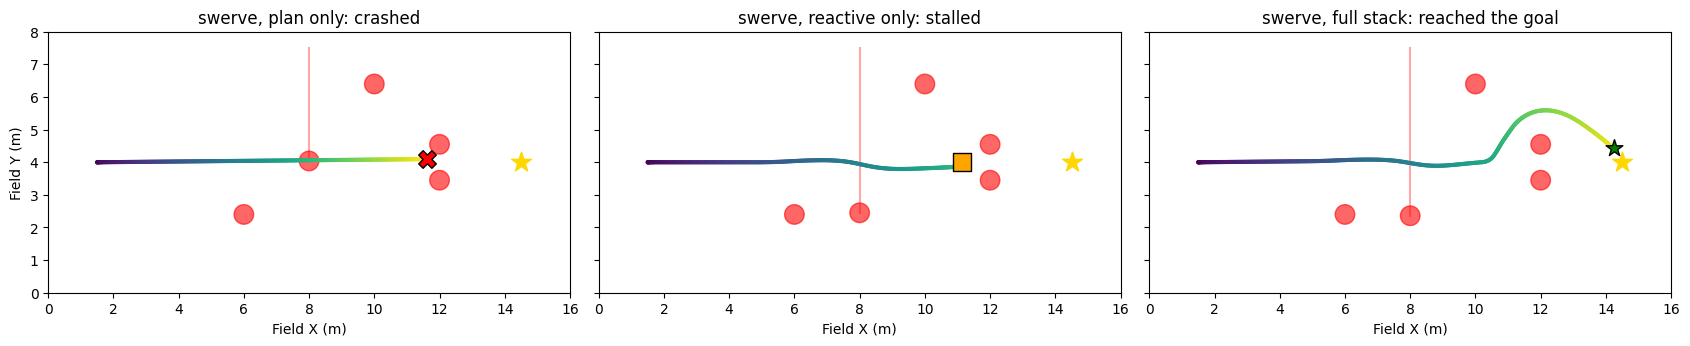

In [27]:
world = make_world("keeps going", 99.0)
swerve_runs = {mode: simulate_swerve(mode, world) for mode in ("plan only", "reactive only", "full stack")}
unicycle_full = runs["full stack"]          # the unicycle full-stack run from earlier, in this same world

print(f"{'':<22}{'outcome':<20}{'time (s)':>9}{'closest approach (m)':>22}{'replans':>9}")
for mode, log in swerve_runs.items():
    print(f"{'swerve, ' + mode:<22}{log['outcome']:<20}{log['t'][-1]:>9.1f}{log['closest']:>22.2f}{log['replans']:>9}")
print(f"{'unicycle, full stack':<22}{unicycle_full['outcome']:<20}{unicycle_full['t'][-1]:>9.1f}{closest_approach(unicycle_full):>22.2f}{len(unicycle_full['replans']):>9}")

fig, axes = plt.subplots(1, 3, figsize=(17, 3.8), sharey=True)
for ax, (mode, log) in zip(axes, swerve_runs.items()):
    ax.scatter(log["pos"][:, 0], log["pos"][:, 1], c=log["t"], s=4, cmap="viridis", zorder=4)
    for o in world:
        if not o.is_static():
            track = np.array([o.position(t) for t in np.linspace(0, log["t"][-1], 30)])
            ax.plot(track[:, 0], track[:, 1], "-", color="red", alpha=0.35)
        ax.add_patch(plt.Circle(o.position(log["t"][-1]), 0.3, color="red", alpha=0.6, zorder=3))
    marker = {"crashed": ("X", "red"), "stalled": ("s", "orange"), "reached the goal": ("*", "green")}[log["outcome"]]
    ax.scatter(*log["pos"][-1], marker=marker[0], s=160, color=marker[1], zorder=6, edgecolor="black")
    ax.scatter(*GOAL, marker="*", s=220, color="gold", zorder=5)
    style_field(ax, f"swerve, {mode}: {log['outcome']}")
axes[0].set_ylabel("Field Y (m)")
plt.tight_layout()
plt.show()

The same match gives the same pattern of results. Plan-only still crashes, though into the gate this time, since a swerve robot can sidestep the opponent. Reactive-only still stalls at the gate, but now it's the textbook version of the problem. It stops about a meter from both gate robots, which push back equally while the goal pulls it forward. The full stack reaches the goal with the same single replan, in about ten seconds against seventeen for the unicycle.

So the structure of the stack carries over. Every layer gets simpler, and the robot gets faster, because it never has to loop around to turn or slow down in order to steer.

## What This Leaves Out

This is still a teaching simulator, so what is missing?

We assumed the stack already knows which detection belongs to which robot. The Kalman filter here is simply told each obstacle's identity. A real tracker has to work that out itself, as `05`'s SORT pipeline does, and it can get it wrong when two robots cross paths.

We assumed futures chosen by hand. The multi-hypothesis predictor's four hypotheses and their probabilities were set by us. A trained model like `07`'s would learn them from data, and its probabilities would only be as good as that data.

We assumed the planner reasons about space and not time. Even with predictions, a predicted path becomes a region of the field that's blocked for the next several seconds, because the planner only knows how to plan in position. Planning in space and time, like `09`'s Problem A, would let it slip behind a robot that has already moved on. This is why a cautious planner sometimes finds no path at all, and has to be told to relax.

We did not solve actuator lag. Driving slower and steering from the predicted pose did not help, and a longer lookahead made things worse. The real answer is a controller that models the drivetrain explicitly, which is beyond what we built here.

We assumed the reactive layer only needs to know about robots. It doesn't know about the field walls, which is why a hard swerve could end with the robot against one.

We assumed a simple collision model. Every robot is a circle. Real robots have shapes, and a swerve robot's footprint changes as it rotates.

We assumed every layer is hand-written. A learned policy could replace some of them, and `ml_resources/rl_primer/05-rl-in-the-autonomy-stack.ipynb` tests which ones, and what a supervisor like this one does for a learned policy that meets a world it wasn't trained on.

A real team couldn't validate a stack by running a simulator like this one alone. As `09` described for AVs, that takes simulation at scale, shadow-mode testing on the real robot, and careful tracking of every time something went wrong. What the simulator is good for is seeing how the layers depend on each other, and that part carries over.

If the goal is a real robot, `frc_resources/09_autonomy_stack_in_frc` is the next stop. It maps each of these layers onto the FRC tools that do the same job (PathPlanner, the pose estimator, command-based code), says what you'd still have to write yourself, and lists where this simulator's assumptions break on real hardware.

## Try It Yourself

Delete the two gate robots from `OBSTACLES` (they're the last two entries in the world cell) and re-run everything from that cell down. Which of the three stacks reach the goal now? Does the full stack beat reactive-only, or lose to it? What does that say about when a planner earns its keep?

Put the gate back, then move its two robots apart by changing their y positions (they start at `3.45` and `4.55`). How far apart do they need to be before the reactive-only run gets through? Does the full stack's behavior change at that point?

Add a third parked robot to `OBSTACLES`, for example `Obstacle("parked C", (7.0, 5.0))`, and re-run. Where does reactive-only get stuck now, and does the full stack still make it? Why is a local minimum something you can't fix by tuning the reactive layer alone?

Change the gate's `appears_at` from `6.0` to `2.0`, so it shows up while the robot is still far away. When does the supervisor replan this time? Then go back to `6.0` and change the `horizon` default in `path_is_blocked` from `8.0` to `3.0`. How does the timing of the replan change? Look at the failed attempts as well as the successful one, and think about what a short look-ahead costs and what it saves.

Make the opponent faster by changing its velocity to `(0.0, -0.9)`. What does the plan-only run do now, and does the full stack still make it through?

Finally, set `CREEP_FLOOR` to `0.0`, so the reactive layer is allowed to brake all the way down. Does the full stack still reach the goal? How does its arrival time compare, and why would a robot that brakes harder end up slower, even though it's being more careful?

For the relaxed assumptions: raise `POSITION_NOISE` from `0.15` to `0.4`, then separately raise `DROPOUT` from `0.1` to `0.5`, and re-run the perception comparison. Which hurts the stack more, noisier detections or missing ones? Why would missing detections be so costly for a filter?

Edit the weights in `multi_hypothesis_predictor`, for example by giving "keeps going" `0.7` and each of the other three `0.1`, and re-run the sweep. How does the chart change? What does that say about relying on probabilities that someone chose by hand?

Change the delay in the delay comparison from `0.5` to `1.0`, and the lag in the lag comparison from `0.6` to `0.3`. Which of the two matters more, and at what size does each stop mattering?

In the lag experiment, add `lookahead=2.0` to the settings. A longer lookahead is a common way to calm a path tracker down. What happens here, and why might it make things worse for this stack?

Re-run the swerve comparison with `SWERVE_ACCEL` set to `1.0`, so the drivetrain is much more sluggish. Does the swerve robot still reach the goal, and what happens to its lead over the unicycle?

## Resources

- Coulter, R.C. (1992). "Implementation of the Pure Pursuit Path Tracking Algorithm." Carnegie Mellon University Robotics Institute Technical Report CMU-RI-TR-92-01. The original paper behind the tracker used here, and the one `04b` implements (paper).
- Khatib, O. (1986). "Real-Time Obstacle Avoidance for Manipulators and Mobile Robots." *International Journal of Robotics Research*. The original artificial potential field paper, the basis for the reactive layer (paper).
- Dolgov, D., Thrun, S., Montemerlo, M., & Diebel, J. (2010). "Path Planning for Autonomous Vehicles in Unknown Semi-structured Environments." *International Journal of Robotics Research*. The Hybrid A\* paper, the basis for the global planner (paper).
- Paden, B., Čáp, M., Yong, S. Z., Yershov, D., & Frazzoli, E. (2016). "A Survey of Motion Planning and Control Techniques for Self-Driving Urban Vehicles." *IEEE Transactions on Intelligent Vehicles*. A broad survey of how real autonomous vehicles divide planning and control into layers much like the ones built here (paper).
- `back_end_resources/systems_primer/04b_motion_control_and_trajectories` and `09-planning-and-av-context.ipynb`, where the tracker, planner, and reactive layer were first built.
- `frc_resources/09_autonomy_stack_in_frc`, which maps this stack onto PathPlanner, WPILib's pose estimator, and command-based code, and lays out a build order for a real vision-assisted autonomous mode.